# 04. Étapes 1 et 2 : chargement robuste, découpage et prétraitement

**Projet AutoML, Challenge Machine Learning (M1 IA, Le Mans Université)**

Ce notebook montre, avec des exemples concrets, ce que font les étapes 1 et 2 du package `automl/` :

1. **Chargement** des 6 jeux et **détection automatique de la tâche** (`automl/data.py`, `automl/inspection.py`).
2. **Découpage adaptatif** train / validation / test selon la taille du jeu.
3. **Stratification** : train, validation et test gardent la même répartition de la cible, y compris en multi-label et en régression.
4. **Pièges d'un jeu de test secret** : on fabrique de petits fichiers piégés et on regarde comment ils sont lus.
5. **Prétraitement** : nombre de variables avant / après, absence de valeurs manquantes ou infinies.

Explications détaillées : `docs/STEPS_1_2_ROBUSTNESS.md`.

In [1]:
import os, sys, time, io, contextlib, tempfile
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Importer le package automl/ du projet sans l'installer
sys.path.insert(0, os.path.abspath(".."))
DATA = os.path.abspath(os.path.join("..", "dataset"))
JEUX = ["data_A", "data_B", "data_C", "data_D", "data_E", "data_F"]
plt.rcParams["figure.dpi"] = 90
print("Données lues dans :", DATA)

Données lues dans : /Users/zakariafarach/Documents/UNIV/M1_IA/S1/CraftedAutoML/mon_projet/dataset


In [2]:
from automl.data import load_dataset, split_data, adaptive_split_sizes
from automl.inspection import detect_task, inspect_data
from automl.preprocessing import build_preprocessor

## 1. Chargement des 6 jeux et détection de la tâche

La tâche est déduite **uniquement** du fichier `.solution` (nombre de colonnes, valeurs entières ou non,
lignes qui somment à 1...). Aucun nom de jeu n'est codé en dur : c'est ce qui permet de traiter un jeu secret.

In [3]:
datasets, lignes = {}, []
for nom in JEUX:
    t0 = time.time()
    ds = load_dataset(os.path.join(DATA, nom))
    duree = time.time() - t0
    task = detect_task(ds.y)
    datasets[nom] = (ds, task)
    lignes.append({
        "jeu": nom,
        "lignes": ds.X.shape[0],
        "variables": ds.X.shape[1],
        "format": "creux" if sp.issparse(ds.X) else "dense",
        "tâche détectée": task.task,
        "sorties": task.n_outputs,
        "chargement (s)": round(duree, 1),
    })
pd.DataFrame(lignes).set_index("jeu")

,lignes,variables,format,tâche détectée,sorties,chargement (s)
jeu,,,,,,
data_A,34190,24,dense,multilabel,3,0.0
data_B,5000,16,dense,regression,1,0.0
data_C,15000,1568,dense,multiclass_onehot,10,0.7
data_D,2984,144,dense,binary,1,0.0
data_E,3140,259,dense,binary,1,0.0
data_F,13142,61188,creux,multiclass_onehot,20,0.5


## 2. Découpage adaptatif

Avant, tous les jeux étaient coupés en 70 % / 15 % / 15 %. Maintenant la part de validation dépend de la taille N
(fonction `adaptive_split_sizes`) :

- **petit jeu** : on garde une grande part de validation, sinon le score de validation est trop instable ;
- **grand jeu** : quelques milliers de lignes de validation suffisent, le reste sert à l'entraînement.

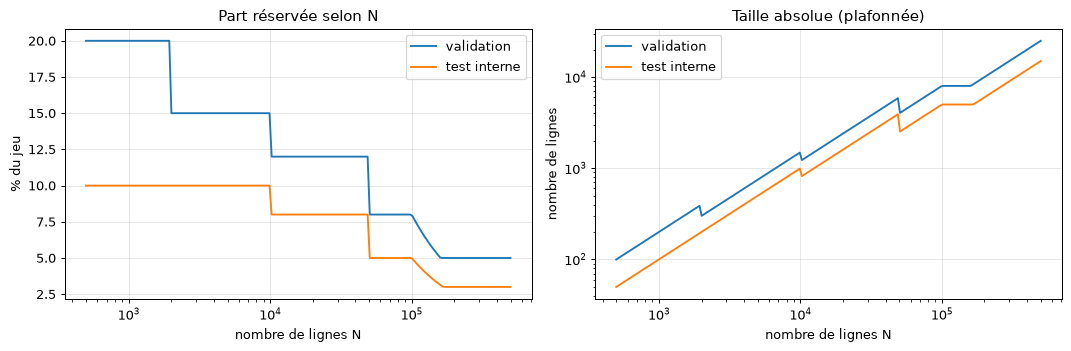

In [4]:
N = np.logspace(np.log10(500), np.log10(500000), 200).astype(int)
parts = np.array([adaptive_split_sizes(n) for n in N])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(N, parts[:, 0] * 100, label="validation")
axes[0].plot(N, parts[:, 1] * 100, label="test interne")
axes[0].set_xscale("log"); axes[0].set_xlabel("nombre de lignes N"); axes[0].set_ylabel("% du jeu")
axes[0].set_title("Part réservée selon N"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(N, parts[:, 0] * N, label="validation")
axes[1].plot(N, parts[:, 1] * N, label="test interne")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("nombre de lignes N")
axes[1].set_ylabel("nombre de lignes"); axes[1].set_title("Taille absolue (plafonnée)")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

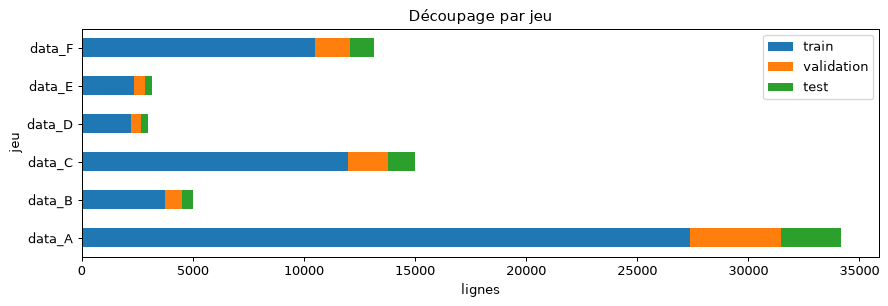

,train,validation,test,% validation,% test,stratifié
jeu,,,,,,
data_A,27351,4103,2736,12,8,oui
data_B,3750,750,500,15,10,oui
data_C,12000,1800,1200,12,8,oui
data_D,2237,448,299,15,10,oui
data_E,2355,471,314,15,10,oui
data_F,10513,1577,1052,12,8,oui


In [5]:
lignes = []
for nom, (ds, task) in datasets.items():
    strat = task.stratify_labels(task.encode_y(ds.y))
    X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(ds.X, ds.y, strat)
    v, t = adaptive_split_sizes(ds.X.shape[0])
    lignes.append({"jeu": nom, "train": X_tr.shape[0], "validation": X_va.shape[0], "test": X_te.shape[0],
                   "% validation": round(100 * v), "% test": round(100 * t),
                   "stratifié": "oui" if strat is not None else "non"})
tab = pd.DataFrame(lignes).set_index("jeu")
tab[["train", "validation", "test"]].plot.barh(stacked=True, figsize=(10, 3.5), title="Découpage par jeu")
plt.xlabel("lignes"); plt.tight_layout(); plt.show()
tab

## 3. Stratification : même répartition dans chaque sous-ensemble

`scikit-learn` ne sait stratifier qu'une classe simple. `TaskInfo.stratify_labels` construit une étiquette 1-D :

- **multi-label (`data_A`)** : chaque combinaison de labels devient un entier, par exemple `[1, 0, 1]` donne 5 ;
- **régression (`data_B`)** : le décile de la cible.

Si la stratification fonctionne, les barres (ou les courbes) des trois sous-ensembles se superposent.

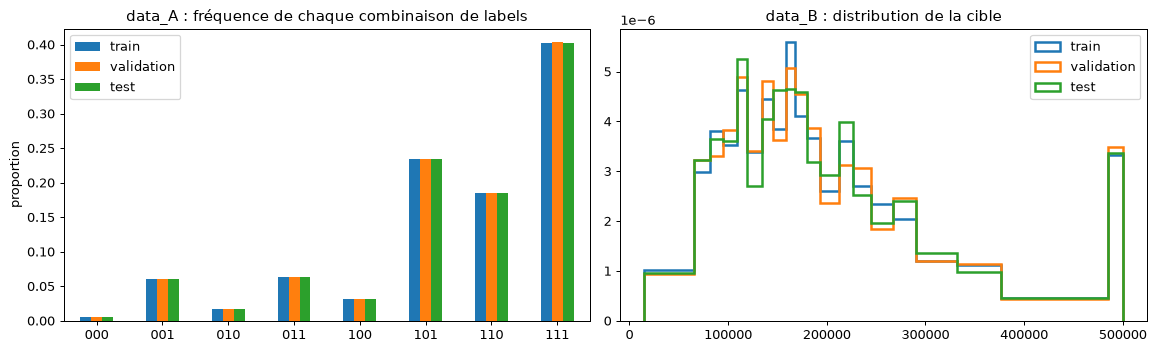

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ds, task = datasets["data_A"]
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(ds.X, ds.y, task.stratify_labels(task.encode_y(ds.y)))
freq = {}
for nom_split, y in [("train", y_tr), ("validation", y_va), ("test", y_te)]:
    combos = ["".join(str(int(v)) for v in row) for row in y]
    freq[nom_split] = pd.Series(combos).value_counts(normalize=True)
pd.DataFrame(freq).sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("data_A : fréquence de chaque combinaison de labels"); axes[0].set_ylabel("proportion")

ds, task = datasets["data_B"]
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(ds.X, ds.y, task.stratify_labels(task.encode_y(ds.y)))
bins = np.quantile(ds.y, np.linspace(0, 1, 21))
for nom_split, y in [("train", y_tr), ("validation", y_va), ("test", y_te)]:
    axes[1].hist(y, bins=bins, density=True, histtype="step", linewidth=2, label=nom_split)
axes[1].set_title("data_B : distribution de la cible"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Les pièges d'un jeu de test secret

On écrit de petits fichiers volontairement piégés dans un dossier temporaire, puis on les lit comme le ferait `predict`,
**avec les informations apprises au train** (`ds.meta` : largeur, codage du texte, décalage des indices creux).

In [7]:
def write_dataset(dossier, nom, lignes, types, solution=None):
    os.makedirs(dossier, exist_ok=True)
    with open(os.path.join(dossier, nom + ".data"), "w") as f:
        f.write("\n".join(lignes) + "\n")
    with open(os.path.join(dossier, nom + ".type"), "w") as f:
        f.write("\n".join(types) + "\n")
    if solution is not None:
        with open(os.path.join(dossier, nom + ".solution"), "w") as f:
            f.write("\n".join(solution) + "\n")
    return dossier

tmp = tempfile.mkdtemp()
types = ["Categorical", "Numerical", "Numerical"]
train = write_dataset(os.path.join(tmp, "train"), "jeu",
               ["rouge 1.5 2", "bleu inf 3", "rouge 0.5 ?", "vert 2 4"], types, ["0", "1", "0", "1"])
ds_train = load_dataset(train)
print("Codage du texte appris au train :", ds_train.meta.string_encoders)
pd.DataFrame(ds_train.X, columns=["couleur (codée)", "num_1", "num_2"])

Codage du texte appris au train : {0: {'bleu': 0.0, 'rouge': 1.0, 'vert': 2.0}}


,couleur (codée),num_1,num_2
0,1.0,1.5,2.0
1,0.0,NaN,3.0
2,1.0,0.5,NaN
3,2.0,2.0,4.0


Au train : `inf` et `?` deviennent des valeurs manquantes (`NaN`), le texte est codé en nombres.

Au test ci-dessous :
- ligne 1 : `violet` n'a jamais été vu, `oops` est du texte dans une colonne numérique ;
- ligne 2 : `bleu` doit recevoir **le même code qu'au train** ;
- la dernière colonne est absente du fichier de test.

In [8]:
test = write_dataset(os.path.join(tmp, "test"), "jeu", ["violet oops", "bleu 1"], types[:2])
ds_test = load_dataset(test, meta=ds_train.meta)
print("Forme lue :", ds_test.X.shape, "(3 colonnes, comme au train)")
pd.DataFrame(ds_test.X, columns=["couleur (codée)", "num_1", "num_2"])

Forme lue : (2, 3) (3 colonnes, comme au train)


,couleur (codée),num_1,num_2
0,NaN,NaN,NaN
1,0.0,1.0,NaN


In [9]:
# Format creux : indices commençant à 0, puis au test un indice inconnu (99) et une ligne vide
train_sp = write_dataset(os.path.join(tmp, "train_sp"), "sp", ["0:1 2:3", "1:2"], ["Numerical"] * 3, ["0", "1"])
ds_sp = load_dataset(train_sp)
print("Décalage des indices détecté :", ds_sp.meta.sparse_offset, "(0 = numérotation à partir de 0)")
test_sp = write_dataset(os.path.join(tmp, "test_sp"), "sp", ["0:1 99:4", ""], ["Numerical"] * 3)
X = load_dataset(test_sp, meta=ds_sp.meta).X
print("Test lu :", X.shape, "-> l'indice 99 est ignoré, la ligne vide est gardée")
X.toarray()

Décalage des indices détecté : 0 (0 = numérotation à partir de 0)
Test lu : (2, 3) -> l'indice 99 est ignoré, la ligne vide est gardée


array([[1., 0., 0.],
       [0., 0., 0.]])

## 5. Prétraitement : avant / après

Le prétraitement (étape 2, Lionel) est ajusté **sur le train uniquement** puis appliqué à la validation et au test.
On vérifie le nombre de variables avant / après et l'absence de `NaN` ou de valeurs infinies.

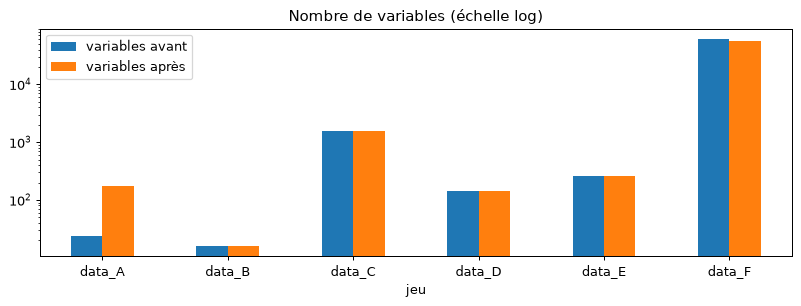

,variables avant,variables après,NaN ou infini,colonnes constantes retirées,colonnes passées en log,durée (s)
jeu,,,,,,
data_A,24,173,0,0,6,0.1
data_B,16,16,0,0,8,0.0
data_C,1568,1568,0,0,1081,2.1
data_D,144,144,0,0,2,0.0
data_E,259,259,0,0,0,0.1
data_F,61188,55697,0,5491,0,0.1


In [10]:
lignes = []
for nom, (ds, task) in datasets.items():
    strat = task.stratify_labels(task.encode_y(ds.y))
    X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(ds.X, ds.y, strat)
    profil = inspect_data(X_tr, ds.types, y_tr)
    profil.task = task
    prep = build_preprocessor(profil)
    t0 = time.time()
    Xt = prep.fit_transform(X_tr, task.encode_y(y_tr))
    Xv = prep.transform(X_va)
    valeurs = np.concatenate([(Xt.data if sp.issparse(Xt) else Xt).ravel(), (Xv.data if sp.issparse(Xv) else Xv).ravel()])
    lignes.append({"jeu": nom, "variables avant": ds.X.shape[1], "variables après": Xt.shape[1],
                   "NaN ou infini": int((~np.isfinite(valeurs)).sum()),
                   "colonnes constantes retirées": len(profil.constant),
                   "colonnes passées en log": len(profil.skewed),
                   "durée (s)": round(time.time() - t0, 1)})
tab = pd.DataFrame(lignes).set_index("jeu")
tab[["variables avant", "variables après"]].plot.bar(logy=True, rot=0, figsize=(9, 3.5),
                                                       title="Nombre de variables (échelle log)")
plt.tight_layout(); plt.show()
tab

## Ce qu'il faut retenir

- Les 6 jeux sont chargés et leur tâche est détectée sans aucun nom codé en dur.
- Le découpage s'adapte à la taille du jeu et garde la même répartition de la cible dans chaque sous-ensemble.
- Les pièges courants d'un jeu secret (texte, `?`, `inf`, colonne manquante, modalité ou indice inconnus) ne font pas planter le chargement.
- Après prétraitement, aucune valeur manquante ou infinie ne reste : les modèles de l'étape 3 peuvent s'entraîner.